# GesturePod EDA
Explore the IMU gesture dataset. Training lives in `train.py`; this notebook is for looking at the signals.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
import numpy as np, matplotlib.pyplot as plt
from src.gesturehub import data

X, y, classes = data.load_dataset('dataset/dataset', target_len=128)
print('samples', X.shape, 'classes', classes)
for i, c in enumerate(classes):
    print(f'{c}: {(y==i).sum()}')

samples (80, 128, 6) classes ['double_tap', 'left_twist', 'right_twist', 'swirl']
double_tap: 20
left_twist: 20
right_twist: 20
swirl: 20


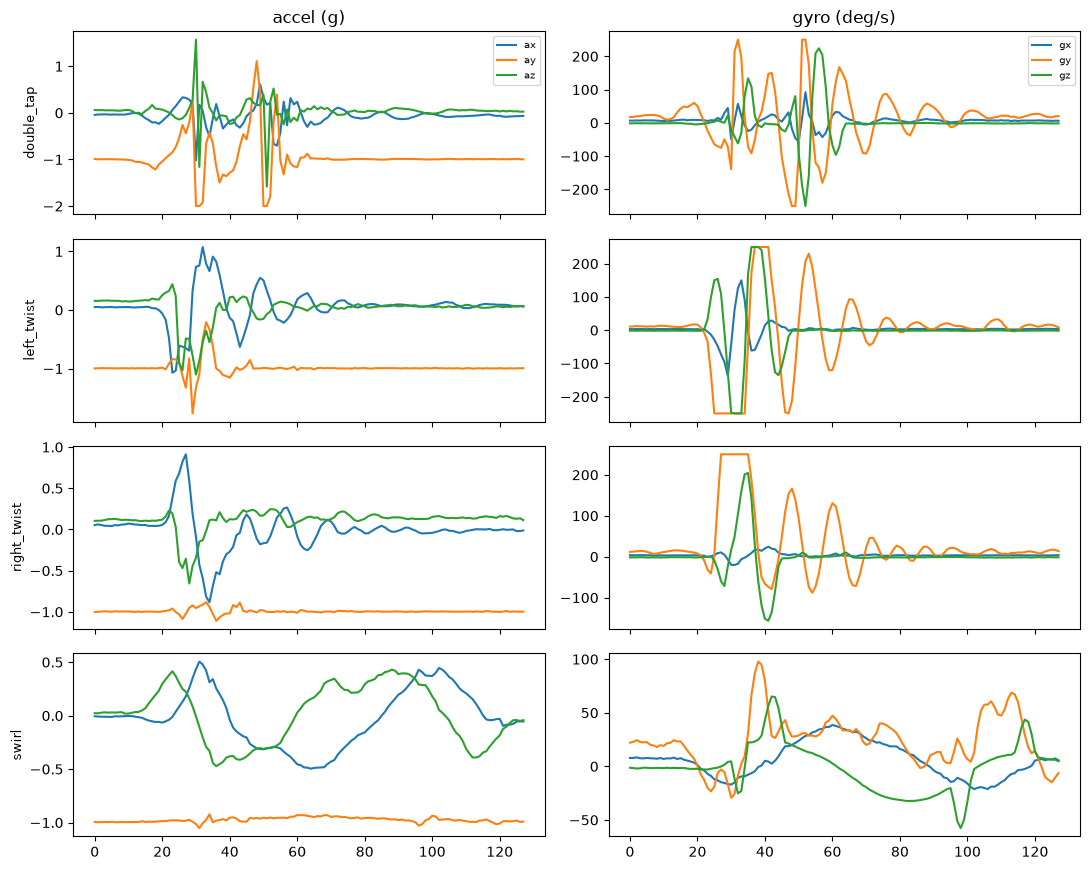

In [2]:
# one resampled example per class: accel (top) + gyro (bottom)
fig, axes = plt.subplots(len(classes), 2, figsize=(11, 2.2*len(classes)), sharex=True)
for i, c in enumerate(classes):
    ex = X[np.argmax(y==i)]
    for ch, lbl in zip(range(3), ['ax','ay','az']):
        axes[i,0].plot(ex[:,ch], label=lbl)
    for ch, lbl in zip(range(3,6), ['gx','gy','gz']):
        axes[i,1].plot(ex[:,ch], label=lbl)
    axes[i,0].set_ylabel(c, fontsize=9)
axes[0,0].set_title('accel (g)'); axes[0,1].set_title('gyro (deg/s)')
axes[0,0].legend(fontsize=7); axes[0,1].legend(fontsize=7)
plt.tight_layout(); plt.show()

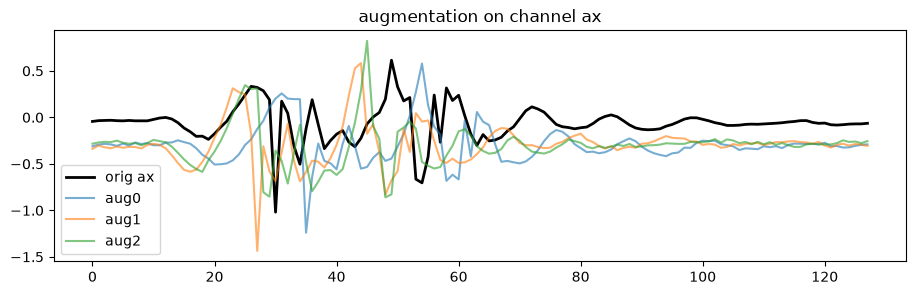

In [3]:
# augmentation preview: original vs 3 augmented copies of one gesture
from src.gesturehub import augment
rng = np.random.default_rng(0)
ex = X[0]
plt.figure(figsize=(11,3))
plt.plot(ex[:,0], 'k', lw=2, label='orig ax')
for k in range(3):
    plt.plot(augment.augment_once(ex, rng)[:,0], alpha=0.6, label=f'aug{k}')
plt.legend(); plt.title('augmentation on channel ax'); plt.show()

## Train
Run in a terminal (long):
```
.venv/Scripts/python.exe train.py
```
Exports int8 TFLite + C sources to `out/` for the ESP32.